In [ ]:
from experiment_tracking.exp_tracker import fetch_experiment_results
import pandas as pd
from datasets.Harmonized_Datasets import harmonize
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report
import gseapy as gp


In [35]:
datasets = harmonize()

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [20]:
def plot_roc_auc_curve(y_true, y_prob):
 
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_score = roc_auc_score(y_true, y_prob)

    plt.tight_layout(pad=5)
    plt.plot(fpr, tpr, label=f"AUC: {round(auc_score, 3)}", linewidth=2, color="lightblue")
    plt.plot([0,1], [0,1], color="salmon", label="AUC: 0.5", linestyle="dashed")
    plt.legend(loc=4)
    plt.xlabel("fpr")
    plt.ylabel("tpr")
    plt.yticks(rotation=0)


def plot_confusion_matrix(y_true, y_pred):

    conf_matrix = confusion_matrix(y_true, y_pred)
    sns.heatmap(conf_matrix, annot=True, fmt="g", cmap=sns.color_palette("Blues", as_cmap=True))
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
 

In [33]:
exp_dir = "../../outputs/experiments/t11_14_degs2026-09-05_08:37:35/" # the title thing is flawed its not acc loo
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"
cv_results_df = pd.read_csv(exp_dir + "cv_results.csv")
ev_results_df = pd.read_csv(exp_dir + "ev_results.csv")

In [ ]:
# focus on moffitt results

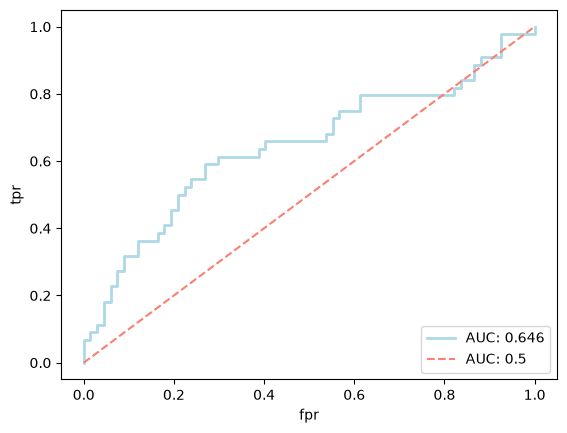

In [28]:
plot_roc_auc_curve(cv_results_df['y_true'], cv_results_df['y_prob'])


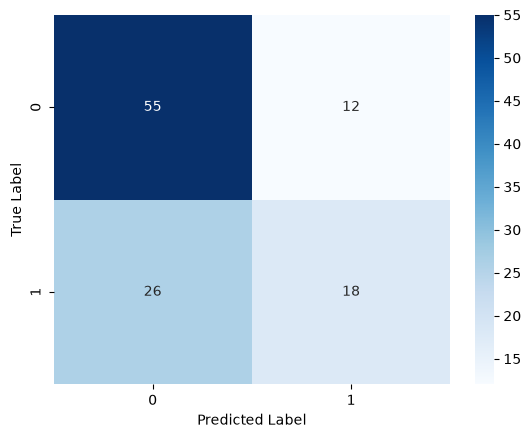

In [30]:
plot_confusion_matrix(cv_results_df['y_true'], cv_results_df['y_pred'])

In [38]:
mf_ad = datasets["Moffitt"]
survival_df = pd.read_excel("../../data/Moffitt/Clinical_Metadata/can-26-1082_table_s10_suppst10.xlsx")
survival_df.columns = survival_df.iloc[0]
survival_df = survival_df.set_index("RNAseq_SLID")

#survival_df = survival_df.drop(index=1)

survival_df = survival_df.loc[~survival_df.index.duplicated(keep="first")]
patient_index = list(set(mf_ad.to_df().index) & set(survival_df.index))
survival_df = survival_df[['OS_days', 'OS_status', 'PFS_days', "PFS_status"]].loc[patient_index]


In [40]:
# OS
os_df = survival_df[survival_df[['OS_days', "OS_status"]].notna()]
os_df['OS_status'] = [1 if s == 'alive' else 0 for s in os_df['OS_status']]

In [44]:
cv_results_df = cv_results_df.set_index('samples')


KeyError: "None of ['samples'] are in the columns"